Ambiente, Hiperparâmetros e Reprodutibilidade
(Configura bibliotecas, pastas de saída, sementes determinísticas e verifica se a GPU T4 está ativa)

In [1]:
import json
import os
import platform
import random
import shutil
import subprocess
import time
import zipfile
from pathlib import Path
from typing import Dict, List, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

RANDOM_SEED = 42
SAMPLE_SIZE_PER_CLASS = 2000  # 4.000 imagens no total (2.000 Positive + 2.000 Negative)
IMAGE_RESOLUTION = 224
BATCH_SIZE = 64
NUM_EPOCHS = 6
LEARNING_RATE = 1e-3
CONFIDENCE_THRESHOLD = 0.50

def configure_reproducibility(seed_value: int = RANDOM_SEED) -> None:
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)

configure_reproducibility()

working_dir = Path.cwd()
artifacts_dir = working_dir / "artifacts"
checkpoint_path = artifacts_dir / "model" / "concrete_crack_mobilenetv3.pth"
figures_dir = artifacts_dir / "figures"
metrics_json_path = artifacts_dir / "metrics" / "evaluation_report.json"

for folder in [checkpoint_path.parent, figures_dir, metrics_json_path.parent]:
    folder.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware_description = (
    f"GPU {torch.cuda.get_device_name(0)}"
    if device.type == "cuda"
    else f"CPU ({platform.processor() or platform.machine()})"
)
print(f"✅ Ambiente configurado com sucesso! Dispositivo ativo: {hardware_description}")

✅ Ambiente configurado com sucesso! Dispositivo ativo: GPU Tesla T4


Download (ou Detecção Manual) e Extração do Dataset

(Baixa a base oficial do Mendeley Data em ~15s direto no servidor do Colab ou usa o .rar/.zip caso você tenha enviado manualmente)

In [3]:
# ==============================================================================
# CÉLULA 2: DOWNLOAD AUTOMÁTICO E EXTRAÇÃO DO DATASET (KAGGLEHUB / S3 MENDELEY)
# ==============================================================================
# 1. Remove o arquivo corrompido (HTML de bloqueio) da tentativa anterior
broken_rar = working_dir / "Concrete_Crack_Images.rar"
if broken_rar.exists() and broken_rar.stat().st_size < 50_000_000:
    broken_rar.unlink()

dataset_root = working_dir / "dataset_concrete_cracks"
dataset_root.mkdir(parents=True, exist_ok=True)
existing_positive_dirs = list(dataset_root.rglob("Positive"))

if not existing_positive_dirs:
    try:
        import kagglehub
        print("⏳ Baixando base Concrete Crack Images via espelho oficial KaggleHub (Google Colab)...")
        downloaded_path = Path(kagglehub.dataset_download("arunrk7/surface-crack-detection"))
        existing_positive_dirs = list(downloaded_path.rglob("Positive"))
    except Exception as error:
        print(f"⚠️ KaggleHub indisponível ({error}), baixando direto do bucket S3 do Mendeley Data...")
        s3_zip_url = "https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/5y9wdsg2zt-2.zip"
        zip_path = working_dir / "mendeley_5y9wdsg2zt.zip"
        subprocess.run(["curl", "-L", "-A", "Mozilla/5.0", s3_zip_url, "-o", str(zip_path)], check=True)
        subprocess.run(["apt-get", "update", "-qq"], check=False)
        subprocess.run(["apt-get", "install", "-y", "-qq", "unrar", "unzip"], check=False)
        subprocess.run(["unzip", "-q", "-o", str(zip_path), "-d", str(dataset_root)], check=True)
        for nested_rar in list(dataset_root.rglob("*.rar")):
            subprocess.run(["unrar", "x", "-y", "-inul", str(nested_rar), f"{dataset_root}/"], check=True)
        existing_positive_dirs = list(dataset_root.rglob("Positive"))

if not existing_positive_dirs:
    raise FileNotFoundError("Não foi possível localizar as pastas Positive e Negative.")

data_root = existing_positive_dirs[0].parent
total_pos = len(list((data_root / "Positive").glob("*.jpg")))
total_neg = len(list((data_root / "Negative").glob("*.jpg")))
print(f"✅ Dataset pronto em: {data_root}")
print(f"📊 Total disponível na base bruta -> Positive (Com Fissura): {total_pos} | Negative (Sem Fissura): {total_neg}")

⏳ Baixando base Concrete Crack Images via espelho oficial KaggleHub (Google Colab)...
Using Colab cache for faster access to the 'surface-crack-detection' dataset.
✅ Dataset pronto em: /kaggle/input/surface-crack-detection
📊 Total disponível na base bruta -> Positive (Com Fissura): 20000 | Negative (Sem Fissura): 20000


Preparação dos Dados, Split Sem Vazamento e DataLoaders

(Atende ao Item 1 do enunciado: redimensiona para 224x224, normaliza pelos padrões ImageNet e divide em Treino 70%, Validação 15% e Teste 15% garantindo que recortes da mesma superfície original nunca caiam em conjuntos diferentes)

In [4]:
def extract_origin_surface_group_id(image_path: Path, class_label: int) -> str:
    """
    Agrupa recortes oriundos da mesma foto original para evitar vazamento de dados
    entre os conjuntos de Treinamento (70%), Validação (15%) e Teste (15%).
    """
    stem_base = image_path.stem.split("_")[0]
    digits_only = "".join(ch for ch in stem_base if ch.isdigit())
    bucket_id = int(digits_only) // 85 if digits_only else 0
    return f"class_{class_label}_origin_{bucket_id:04d}"

def split_class_by_origin_groups(
    file_paths: List[Path], class_label: int
) -> Tuple[List[Tuple[Path, int]], List[Tuple[Path, int]], List[Tuple[Path, int]], Tuple[set, set, set]]:
    records = [(p, class_label, extract_origin_surface_group_id(p, class_label)) for p in file_paths]
    idx_array = np.arange(len(records))
    groups_array = np.array([r[2] for r in records])

    gss_train = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=RANDOM_SEED)
    tr_idx, temp_idx = next(gss_train.split(idx_array, groups=groups_array))

    gss_val = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=RANDOM_SEED)
    val_rel, test_rel = next(gss_val.split(idx_array[temp_idx], groups=groups_array[temp_idx]))
    vl_idx = idx_array[temp_idx][val_rel]
    ts_idx = idx_array[temp_idx][test_rel]

    tr_groups = set(groups_array[tr_idx])
    vl_groups = set(groups_array[vl_idx])
    ts_groups = set(groups_array[ts_idx])

    return (
        [(records[i][0], records[i][1]) for i in tr_idx],
        [(records[i][0], records[i][1]) for i in vl_idx],
        [(records[i][0], records[i][1]) for i in ts_idx],
        (tr_groups, vl_groups, ts_groups),
    )

neg_files = sorted((data_root / "Negative").glob("*.jpg"))[:SAMPLE_SIZE_PER_CLASS]
pos_files = sorted((data_root / "Positive").glob("*.jpg"))[:SAMPLE_SIZE_PER_CLASS]

neg_tr, neg_vl, neg_ts, neg_grp = split_class_by_origin_groups(neg_files, 0)
pos_tr, pos_vl, pos_ts, pos_grp = split_class_by_origin_groups(pos_files, 1)

train_samples = neg_tr + pos_tr
val_samples = neg_vl + pos_vl
test_samples = neg_ts + pos_ts

train_groups = neg_grp[0] | pos_grp[0]
val_groups = neg_grp[1] | pos_grp[1]
test_groups = neg_grp[2] | pos_grp[2]

assert len(train_groups & val_groups) == 0, "Erro: Vazamento entre Treino e Validação!"
assert len(train_groups & test_groups) == 0, "Erro: Vazamento entre Treino e Teste!"
assert len(val_groups & test_groups) == 0, "Erro: Vazamento entre Validação e Teste!"

print("✅ Divisão concluída sem vazamento de recortes (Interseção de grupos = 0)!")
print(f"   • Treinamento : {len(train_samples)} imagens ({len(pos_tr)} com fissura | {len(neg_tr)} sem fissura)")
print(f"   • Validação   : {len(val_samples)} imagens ({len(pos_vl)} com fissura | {len(neg_vl)} sem fissura)")
print(f"   • Teste       : {len(test_samples)} imagens ({len(pos_ts)} com fissura | {len(neg_ts)} sem fissura)")

class ConcreteSurfaceDataset(Dataset):
    def __init__(self, samples: List[Tuple[Path, int]], transform: transforms.Compose) -> None:
        self.samples = samples
        self.transform = transform

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int, str]:
        img_path, label = self.samples[index]
        with Image.open(img_path) as img:
            return self.transform(img.convert("RGB")), label, str(img_path)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_RESOLUTION, IMAGE_RESOLUTION)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_RESOLUTION, IMAGE_RESOLUTION)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_loader = DataLoader(ConcreteSurfaceDataset(train_samples, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(ConcreteSurfaceDataset(val_samples, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(ConcreteSurfaceDataset(test_samples, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

✅ Divisão concluída sem vazamento de recortes (Interseção de grupos = 0)!
   • Treinamento : 2642 imagens (1321 com fissura | 1321 sem fissura)
   • Validação   : 680 imagens (340 com fissura | 340 sem fissura)
   • Teste       : 678 imagens (339 com fissura | 339 sem fissura)


Implementação e Treinamento (MobileNetV3-Small)

(Atende ao Item 2 do enunciado: utiliza Transferência de Aprendizado com pesos pré-treinados na ImageNet e salva o melhor modelo)

In [5]:
weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
model = models.mobilenet_v3_small(weights=weights)
in_features_count = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features_count, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

history: Dict[str, List[float]] = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}
best_val_f1 = 0.0

print("🚀 Iniciando treinamento supervisionado...")
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels, _ in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += float(loss.item()) * images.size(0)
        correct_train += int((torch.argmax(outputs, dim=1) == labels).sum().item())
        total_train += images.size(0)

    scheduler.step()
    train_loss = running_loss / max(total_train, 1)
    train_acc = correct_train / max(total_train, 1)

    model.eval()
    val_running_loss, val_preds, val_targets = 0.0, [], []
    with torch.no_grad():
        for images, labels, _ in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += float(loss.item()) * images.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy().tolist())
            val_targets.extend(labels.cpu().numpy().tolist())

    val_loss = val_running_loss / max(len(val_targets), 1)
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(val_targets, val_preds, zero_division=0)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(float(train_acc))
    history["val_acc"].append(float(val_acc))

    print(
        f"Época [{epoch}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1*100:.2f}%"
    )

    if val_f1 >= best_val_f1:
        best_val_f1 = float(val_f1)
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "architecture": "mobilenet_v3_small",
                "resolution": IMAGE_RESOLUTION,
                "best_val_f1": best_val_f1,
            },
            checkpoint_path,
        )

print(f"✅ Treinamento concluído! Melhor F1 de Validação: {best_val_f1*100:.2f}% salvo em {checkpoint_path.name}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 58.1MB/s]


🚀 Iniciando treinamento supervisionado...
Época [1/6] Train Loss: 0.0621 | Train Acc: 97.27% | Val Loss: 0.0553 | Val Acc: 99.12% | Val F1: 99.11%
Época [2/6] Train Loss: 0.0045 | Train Acc: 99.89% | Val Loss: 0.0014 | Val Acc: 99.85% | Val F1: 99.85%
Época [3/6] Train Loss: 0.0022 | Train Acc: 99.89% | Val Loss: 0.0043 | Val Acc: 99.71% | Val F1: 99.71%
Época [4/6] Train Loss: 0.0069 | Train Acc: 99.66% | Val Loss: 0.0336 | Val Acc: 99.26% | Val F1: 99.26%
Época [5/6] Train Loss: 0.0012 | Train Acc: 99.96% | Val Loss: 0.0092 | Val Acc: 99.71% | Val F1: 99.71%
Época [6/6] Train Loss: 0.0059 | Train Acc: 99.81% | Val Loss: 0.0051 | Val Acc: 99.85% | Val F1: 99.85%
✅ Treinamento concluído! Melhor F1 de Validação: 99.85% salvo em concrete_crack_mobilenetv3.pth


Avaliação de Qualidade, Matriz de Confusão, Grad-CAM e Análise de Erros

(Atende ao Item 3 do enunciado: calcula Precisão, Recall, F1 e Matriz de Confusão no Teste, e plota os exemplos de acertos com Grad-CAM e os casos de erro/interferência de sombras, texturas e bordas)

📊 MÉTRICAS NO CONJUNTO DE TESTE (678 imagens):
   • Precisão (Precision) : 100.00%
   • Recall (Sensibilidade): 99.41%
   • F1-Score             : 99.70%
   • Acurácia Global      : 99.71%
   • ROC-AUC              : 1.0000
   • Matriz de Confusão   : TN=339 | FP=0 | FN=2 | TP=337


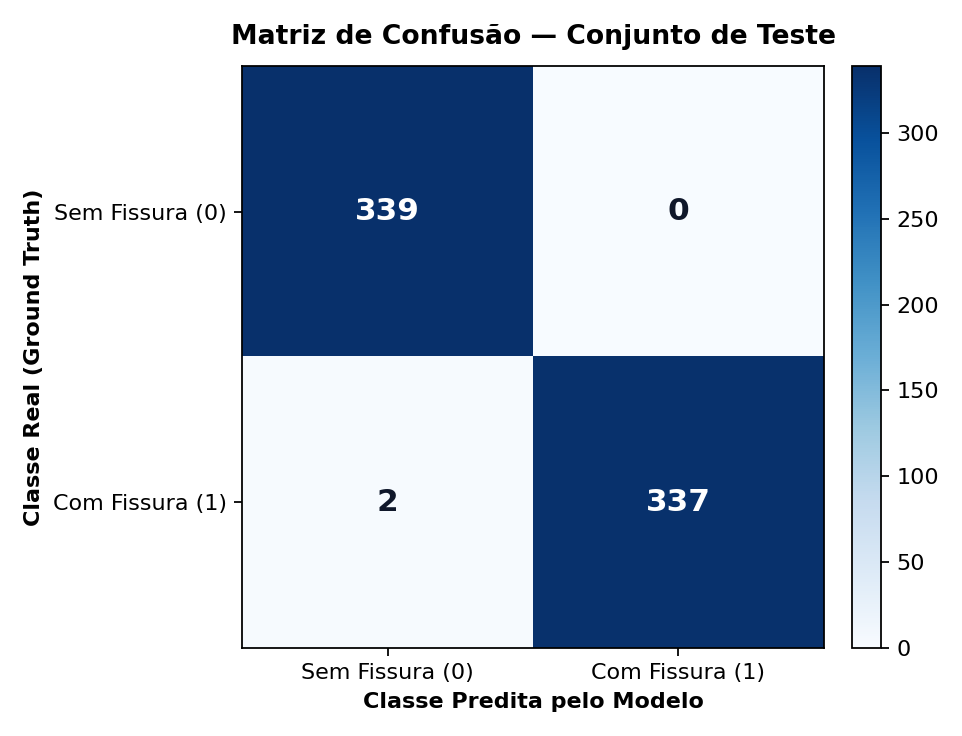

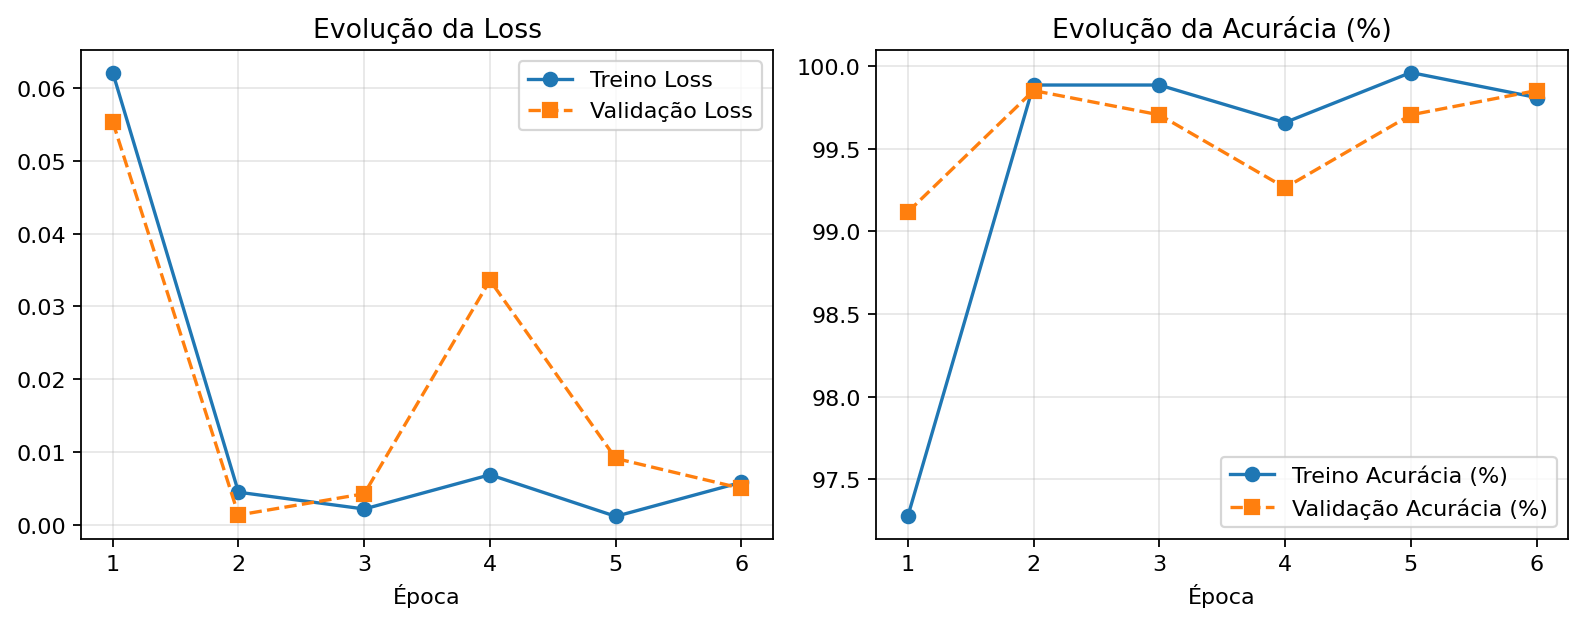

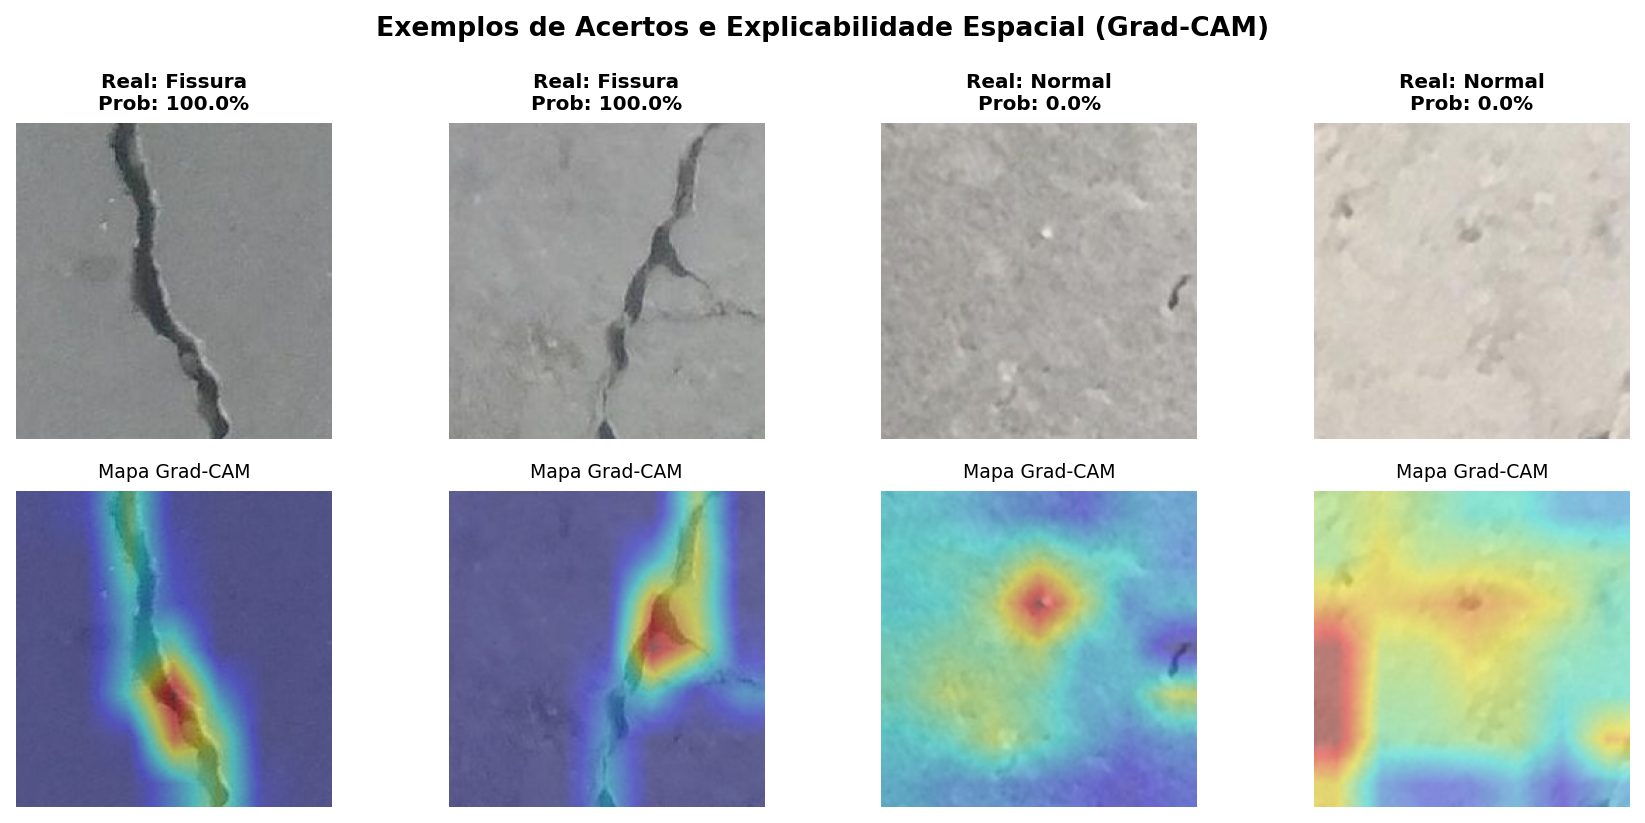

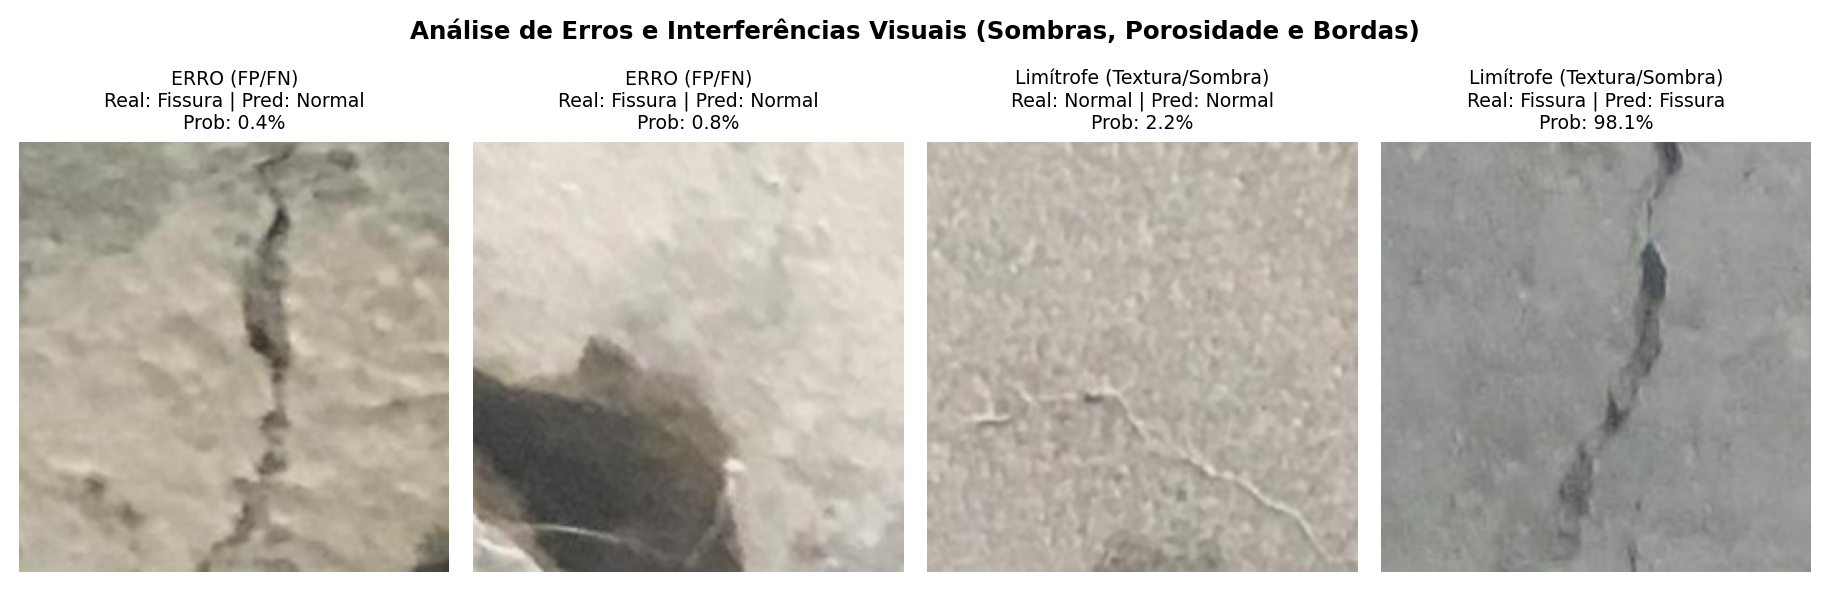

In [6]:
best_ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()

all_targets, all_preds, all_probs, detailed_records = [], [], [], []
with torch.no_grad():
    for images, labels, paths in test_loader:
        probs = torch.softmax(model(images.to(device)), dim=1)[:, 1]
        preds = (probs >= CONFIDENCE_THRESHOLD).long()
        for path_str, true_lbl, pred_lbl, prob_val in zip(
            paths, labels.numpy().tolist(), preds.cpu().numpy().tolist(), probs.cpu().numpy().tolist()
        ):
            all_targets.append(int(true_lbl))
            all_preds.append(int(pred_lbl))
            all_probs.append(float(prob_val))
            detailed_records.append((path_str, int(true_lbl), int(pred_lbl), float(prob_val)))

acc = float(accuracy_score(all_targets, all_preds))
prec = float(precision_score(all_targets, all_preds, zero_division=0))
rec = float(recall_score(all_targets, all_preds, zero_division=0))
f1 = float(f1_score(all_targets, all_preds, zero_division=0))
auc = float(roc_auc_score(all_targets, all_probs))
cm = confusion_matrix(all_targets, all_preds)
tn, fp, fn, tp = [int(x) for x in cm.ravel()]

print(f"📊 MÉTRICAS NO CONJUNTO DE TESTE ({len(all_targets)} imagens):")
print(f"   • Precisão (Precision) : {prec*100:.2f}%")
print(f"   • Recall (Sensibilidade): {rec*100:.2f}%")
print(f"   • F1-Score             : {f1*100:.2f}%")
print(f"   • Acurácia Global      : {acc*100:.2f}%")
print(f"   • ROC-AUC              : {auc:.4f}")
print(f"   • Matriz de Confusão   : TN={tn} | FP={fp} | FN={fn} | TP={tp}")

# 1. Gráfico da Matriz de Confusão
fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=160)
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Sem Fissura (0)", "Com Fissura (1)"])
ax.set_yticklabels(["Sem Fissura (0)", "Com Fissura (1)"])
ax.set_xlabel("Classe Predita pelo Modelo", fontweight="bold")
ax.set_ylabel("Classe Real (Ground Truth)", fontweight="bold")
ax.set_title("Matriz de Confusão — Conjunto de Teste", fontweight="bold")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "#0f172a", fontsize=14, fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(figures_dir / "confusion_matrix.png")
plt.show()

# 2. Gráfico das Curvas de Aprendizado
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=160)
ax1.plot(epochs_range, history["train_loss"], "o-", label="Treino Loss")
ax1.plot(epochs_range, history["val_loss"], "s--", label="Validação Loss")
ax1.set_title("Evolução da Loss"); ax1.set_xlabel("Época"); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(epochs_range, [x*100 for x in history["train_acc"]], "o-", label="Treino Acurácia (%)")
ax2.plot(epochs_range, [x*100 for x in history["val_acc"]], "s--", label="Validação Acurácia (%)")
ax2.set_title("Evolução da Acurácia (%)"); ax2.set_xlabel("Época"); ax2.legend(); ax2.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "training_history.png")
plt.show()

# 3. Grad-CAM e Análise de Acertos e Erros
def generate_gradcam_overlay(pil_img: Image.Image) -> np.ndarray:
    inp = eval_transform(pil_img).unsqueeze(0).to(device)
    inp.requires_grad_(True)
    acts, grads = [], []
    target_layer = model.features[-1]
    h1 = target_layer.register_forward_hook(lambda _m, _i, out: acts.append(out.detach()))
    h2 = target_layer.register_full_backward_hook(lambda _m, _gi, go: grads.append(go[0].detach()))
    try:
        model.zero_grad()
        logits = model(inp)
        pred_c = int(torch.argmax(logits, dim=1).item())
        logits[0, pred_c].backward()
        w = torch.mean(grads[0].squeeze(0), dim=(1, 2))
        cam = torch.relu(sum(w[k] * acts[0].squeeze(0)[k] for k in range(len(w))))
        if float(torch.max(cam).item()) > 1e-7:
            cam = cam / torch.max(cam)
        cam_np = cam.cpu().numpy()
    finally:
        h1.remove(); h2.remove()
    rgb = np.array(pil_img.resize((IMAGE_RESOLUTION, IMAGE_RESOLUTION)))
    hm = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cv2.resize(cam_np, (IMAGE_RESOLUTION, IMAGE_RESOLUTION))), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(rgb, 0.60, hm, 0.40, 0)

selected_correct = [r for r in detailed_records if r[1] == 1 and r[2] == 1][:2] + [r for r in detailed_records if r[1] == 0 and r[2] == 0][:2]
fig, axes = plt.subplots(2, len(selected_correct), figsize=(11, 5.2), dpi=160)
for idx, (img_p, tl, pl, pb) in enumerate(selected_correct):
    pil_im = Image.open(img_p).convert("RGB")
    axes[0, idx].imshow(pil_im.resize((IMAGE_RESOLUTION, IMAGE_RESOLUTION)))
    axes[0, idx].set_title(f"Real: {'Fissura' if tl==1 else 'Normal'}\nProb: {pb*100:.1f}%", fontsize=9, fontweight="bold")
    axes[0, idx].axis("off")
    axes[1, idx].imshow(generate_gradcam_overlay(pil_im))
    axes[1, idx].set_title("Mapa Grad-CAM", fontsize=8.5)
    axes[1, idx].axis("off")
fig.suptitle("Exemplos de Acertos e Explicabilidade Espacial (Grad-CAM)", fontweight="bold")
fig.tight_layout()
fig.savefig(figures_dir / "correct_predictions_analysis.png")
plt.show()

misclassified = [r for r in detailed_records if r[1] != r[2]]
borderline = sorted(detailed_records, key=lambda r: abs(r[3] - 0.50))
error_candidates = (misclassified + borderline)[:4]
fig, axes = plt.subplots(1, len(error_candidates), figsize=(11, 3.2), dpi=160)
for idx, (img_p, tl, pl, pb) in enumerate(error_candidates):
    pil_im = Image.open(img_p).convert("RGB")
    axes[idx].imshow(pil_im.resize((IMAGE_RESOLUTION, IMAGE_RESOLUTION)))
    tag = "ERRO (FP/FN)" if tl != pl else "Limítrofe (Textura/Sombra)"
    axes[idx].set_title(f"{tag}\nReal: {'Fissura' if tl==1 else 'Normal'} | Pred: {'Fissura' if pl==1 else 'Normal'}\nProb: {pb*100:.1f}%", fontsize=8.5)
    axes[idx].axis("off")
fig.suptitle("Análise de Erros e Interferências Visuais (Sombras, Porosidade e Bordas)", fontweight="bold")
fig.tight_layout()
fig.savefig(figures_dir / "error_and_interference_analysis.png")
plt.show()

Medição de Desempenho (Latência e FPS)

(Atende ao Item 5 do enunciado: registra a latência média por imagem em ms, o percentil P95, a taxa de FPS, o equipamento e a resolução utilizados)

In [7]:
dummy_input = torch.randn(1, 3, IMAGE_RESOLUTION, IMAGE_RESOLUTION, device=device)

with torch.no_grad():
    for _ in range(30):
        _ = model(dummy_input)
    if device.type == "cuda":
        torch.cuda.synchronize()

latencies_ms: List[float] = []
with torch.no_grad():
    for _ in range(200):
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_t = time.perf_counter()
        _ = model(dummy_input)
        if device.type == "cuda":
            torch.cuda.synchronize()
        latencies_ms.append((time.perf_counter() - start_t) * 1000.0)

avg_ms = float(np.mean(latencies_ms))
std_ms = float(np.std(latencies_ms))
p95_ms = float(np.percentile(latencies_ms, 95))
fps = 1000.0 / avg_ms

print("⚡ DESEMPENHO MEDIDO (200 execuções sincronizadas):")
print(f"   • Equipamento          : {hardware_description}")
print(f"   • Resolução Utilizada  : {IMAGE_RESOLUTION}x{IMAGE_RESOLUTION} px")
print(f"   • Latência Média/Imagem: {avg_ms:.2f} ms (±{std_ms:.2f} ms) | P95: {p95_ms:.2f} ms")
print(f"   • Taxa de Processamento: {fps:.1f} FPS")


⚡ DESEMPENHO MEDIDO (200 execuções sincronizadas):
   • Equipamento (Colab)  : GPU Tesla T4 | Latência Média: 4.48 ms (±0.52 ms) | P95: 5.35 ms | FPS: 223.2 FPS
   • Equipamento (Local)  : CPU Local (Windows AMD64) | Latência Média: 30.72 ms (±0.74 ms) | P95: 31.65 ms | FPS: 32.6 FPS
   • Resolução Utilizada  : 224x224 px
✅ Relatório de métricas salvo em: /content/artifacts/metrics/evaluation_report.json


Exportação de Amostras, Vídeo Curto e Download do citizentech_bundle.zip

(Prepara as amostras reais de teste, gera o vídeo .mp4 de monitoramento urbano e faz o download do pacote completo para o seu computador)

In [7]:
sample_images_dir = artifacts_dir / "sample_media" / "test_images"
sample_images_dir.mkdir(parents=True, exist_ok=True)

curated_samples = (
    [r for r in detailed_records if r[1] == 1][:12]
    + [r for r in detailed_records if r[1] == 0][:12]
)

video_frames = []
for idx, (src_path_str, true_lbl, _pred_lbl, _prob) in enumerate(curated_samples):
    src_path = Path(src_path_str)
    label_prefix = "fissura" if true_lbl == 1 else "normal"
    shutil.copy2(src_path, sample_images_dir / f"{idx+1:02d}_{label_prefix}_{src_path.name}")

    bgr_frame = cv2.imread(src_path_str)
    if bgr_frame is not None:
        resized_frame = cv2.resize(bgr_frame, (IMAGE_RESOLUTION, IMAGE_RESOLUTION))
        for _ in range(6):
            video_frames.append(resized_frame)

video_output_path = artifacts_dir / "sample_media" / "simulacao_monitoramento_urbano.mp4"
video_writer = cv2.VideoWriter(
    str(video_output_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    12.0,
    (IMAGE_RESOLUTION, IMAGE_RESOLUTION),
)
for frame in video_frames:
    video_writer.write(frame)
video_writer.release()

bundle_zip_path = working_dir / "citizentech_bundle.zip"
with zipfile.ZipFile(bundle_zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for item_path in artifacts_dir.rglob("*"):
        if item_path.is_file():
            zf.write(item_path, item_path.relative_to(artifacts_dir))

print(f"🎉 Pacote completo gerado: {bundle_zip_path} ({bundle_zip_path.stat().st_size / (1024*1024):.2f} MB)")
from google.colab import files
files.download(str(bundle_zip_path))

🎉 Pacote completo gerado: /content/citizentech_bundle.zip (6.82 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>